In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

In [2]:
pois = gpd.read_file("C:/Users/Ā/Documents/python_class/dataset/delhi_pois.geojson")
wards = gpd.read_file("C:/Users/Ā/Documents/python_class/dataset/wards_delhi_c.geojson")


In [3]:
print("POIs:")
display(pois.head())

print("Wards:")
display(wards.head())

print("Number of POIs:", len(pois))
print("Number of wards:", len(wards))

print("POI CRS:", pois.crs)
print("Ward CRS:", wards.crs)

print("POI geometry type:")
print(pois.geometry.geom_type.value_counts())

print("Ward geometry type:")
print(wards.geometry.geom_type.value_counts())


POIs:


,sl_no,PoI_Type,Latitude,Longitude,geometry
0,1,Parks,28.469460,77.122980,POINT (77.12298 28.46946)
1,2,Schools,28.437668,77.141225,POINT (77.14122 28.43767)
2,3,Parks,28.438900,77.142180,POINT (77.14218 28.4389)
3,4,Playgrounds_Open_Source,28.447527,77.138000,POINT (77.138 28.44753)
4,5,amenity,28.452406,77.141672,POINT (77.14167 28.45241)


Wards:


,Ward_Name,Ward_No,geometry
0,DELHI CANTT CHARGE 1,CANT_1,"POLYGON ((77.13228 28.63154, 77.13644 28.62062..."
1,DELHI CANTT CHARGE 2,CANT_2,"POLYGON ((77.15429 28.62335, 77.15501 28.62228..."
2,DELHI CANTT CHARGE 4,CANT_4,"POLYGON ((77.15755 28.57578, 77.15672 28.57564..."
3,DELHI CANTT CHARGE 5,CANT_5,"POLYGON ((77.1348 28.57051, 77.13429 28.57048,..."
4,DELHI CANTT CHARGE 6,CANT_6,"POLYGON ((77.12157 28.59308, 77.12878 28.59029..."


Number of POIs: 50740
Number of wards: 290
POI CRS: EPSG:4326
Ward CRS: EPSG:4326
POI geometry type:
Point    50740
Name: count, dtype: int64
Ward geometry type:
Polygon    290
Name: count, dtype: int64


In [4]:
print("POI columns:")
print(pois.columns)

print("\nWard columns:")
print(wards.columns)

POI columns:
Index(['sl_no', 'PoI_Type', 'Latitude', 'Longitude', 'geometry'], dtype='str')

Ward columns:
Index(['Ward_Name', 'Ward_No', 'geometry'], dtype='str')


In [5]:
pois = pois.rename(columns={
    "sl_no": "id",
    "PoI_Type": "poi_type"
})

wards = wards.rename(columns={
   "Ward_No": "ward_id",
    "Ward_Name": "ward_name"
})

In [6]:
print("POI columns after renaming:")
print(pois.columns)

print("\nWard columns after renaming:")
print(wards.columns)


POI columns after renaming:
Index(['id', 'poi_type', 'Latitude', 'Longitude', 'geometry'], dtype='str')

Ward columns after renaming:
Index(['ward_name', 'ward_id', 'geometry'], dtype='str')


In [7]:
mapping = {

    # Education
    "Schools": "Education",
    "ITI_NIC_2018": "Education",
    "Library_Open_Source": "Education",

    # Health
    "Hospitals": "Health",
    "Pharmacetucal Labs": "Health",
    "Pharmacy": "Health",
    "Psychological_Counselling_Open_Source": "Health",
    "Veterinary Hospital": "Health",

    # Finance
    "ATM": "Finance",
    "Bank Branch": "Finance",
    "Bank Mitra": "Finance",
    "CSC_NIC_Through_API": "Finance",

    # Green space
    "Parks": "Green space",
    "Playgrounds_Open_Source": "Green space",
    "National_Parks_and_Bird_Sanctuaries_Open_Source": "Green space",

    # Commerce
    "shop": "Commerce",
    "Shopping_Malls_Open_Source": "Commerce",
    "Weekly_Markets_Open_Source": "Commerce",

    # Transport & Infrastructure
    "DMRC Stations": "Transport & Infrastructure",
    "Railway Junctions": "Transport & Infrastructure",
    "Level_Crossing_Open_Source": "Transport & Infrastructure",
    "Airports Helipads": "Transport & Infrastructure",
    "Aerodrome": "Transport & Infrastructure",
    "Transport_Nagar_Open_Source": "Transport & Infrastructure",
    "Parking_Open_Source": "Transport & Infrastructure",

    # Public Services & Utilities
    "Post Offices": "Public Services & Utilities",
    "office": "Public Services & Utilities",
    "Police_Station_Open_Source": "Public Services & Utilities",
    "Fire_Stations_Open_Source": "Public Services & Utilities",
    "Fuel_Stations_Open_Source": "Public Services & Utilities",
    "Toilets_Open_Source": "Public Services & Utilities",

    # Leisure, Tourism & Culture
    "Sports Facilities": "Leisure, Tourism & Culture",
    "Stadium": "Leisure, Tourism & Culture",
    "Golf_Course_Open_Source": "Leisure, Tourism & Culture",
    "Cinemas_Open_Source": "Leisure, Tourism & Culture",
    "tourism": "Leisure, Tourism & Culture",
    "Heritage & Tourism": "Leisure, Tourism & Culture",
    "historic": "Leisure, Tourism & Culture",
    "Museum_Tourism_Department": "Leisure, Tourism & Culture",
    "Lodging_Open_Source": "Leisure, Tourism & Culture"
}


In [8]:
pois["category"] = (
    pois["poi_type"]
    .map(mapping)
    .fillna("Other")
)

In [9]:

# ------------------------------------------------------------
# 6. CHECK CRS
# ------------------------------------------------------------

print("POI CRS:", pois.crs)
print("Ward CRS:", wards.crs)


# Make both CRS the same before spatial join

if pois.crs != wards.crs:
    pois = pois.to_crs(wards.crs)


POI CRS: EPSG:4326
Ward CRS: EPSG:4326


In [10]:


# ------------------------------------------------------------
# 7. SPATIAL JOIN
# ------------------------------------------------------------

joined = gpd.sjoin(
    pois,
    wards[
        [
            "ward_id",
            "ward_name",
            "geometry"
        ]
    ],
    how="left",
    predicate="within"
)


# Remove automatically created column

joined = joined.drop(
    columns="index_right"
)



In [11]:

# ------------------------------------------------------------
# 8. SELECT ONLY GREEN-SPACE POIs
# ------------------------------------------------------------

green = joined[
    joined["category"] == "Green space"
].copy()


print(
    "Number of Green-space POIs:",
    len(green)
)

display(green.head())


Number of Green-space POIs: 5750


,id,poi_type,Latitude,Longitude,geometry,category,ward_id,ward_name
0,1,Parks,28.469460,77.122980,POINT (77.12298 28.46946),Green space,175,AYA NAGAR
2,3,Parks,28.438900,77.142180,POINT (77.14218 28.4389),Green space,175,AYA NAGAR
3,4,Playgrounds_Open_Source,28.447527,77.138000,POINT (77.138 28.44753),Green space,175,AYA NAGAR
6,7,Playgrounds_Open_Source,28.445494,77.135171,POINT (77.13517 28.44549),Green space,175,AYA NAGAR
7,8,Playgrounds_Open_Source,28.446882,77.136907,POINT (77.13691 28.44688),Green space,175,AYA NAGAR


In [12]:

# ------------------------------------------------------------
# 9. COUNT GREEN-SPACE POIs IN EACH WARD
# ------------------------------------------------------------

green_counts = (
    green
    .dropna(subset=["ward_name"])
    .groupby(
        [
            "ward_id",
            "ward_name"
        ]
    )
    .size()
    .reset_index(
        name="num_green_pois"
    )
)


print("Green-space POI counts by ward:")

display(green_counts.head())

Green-space POI counts by ward:


,ward_id,ward_name,num_green_pois
0,1,NARELA,21
1,10,TIMAR PUR,26
2,100,KARAM PURA,20
3,101,RAJA GARDEN,27
4,102,RAGHUBIR NAGAR,20


In [13]:

# ------------------------------------------------------------
# 10. MERGE COUNTS BACK TO WARD POLYGONS
# ------------------------------------------------------------

green_ward_map = wards.merge(
    green_counts[
        [
            "ward_id",
            "num_green_pois"
        ]
    ],
    on="ward_id",
    how="left"
)



In [14]:

# ------------------------------------------------------------
# 11. REPLACE MISSING COUNTS WITH 0
# ------------------------------------------------------------

green_ward_map["num_green_pois"] = (
    green_ward_map["num_green_pois"]
    .fillna(0)
)


display(
    green_ward_map[
        [
            "ward_name",
            "num_green_pois"
        ]
    ].head()
)



,ward_name,num_green_pois
0,DELHI CANTT CHARGE 1,0.0
1,DELHI CANTT CHARGE 2,19.0
2,DELHI CANTT CHARGE 4,28.0
3,DELHI CANTT CHARGE 5,13.0
4,DELHI CANTT CHARGE 6,9.0


In [15]:


# ------------------------------------------------------------
# 12. REPROJECT TO EPSG:32643
# ------------------------------------------------------------

green_utm = green_ward_map.to_crs(
    epsg=32643
)


print("Projected CRS:")
print(green_utm.crs)



Projected CRS:
EPSG:32643


In [16]:

# ------------------------------------------------------------
# 13. CALCULATE WARD AREA IN KM²
# ------------------------------------------------------------

green_utm["area_km2"] = (
    green_utm.geometry.area /
    1_000_000
)


display(
    green_utm[
        [
            "ward_name",
            "num_green_pois",
            "area_km2"
        ]
    ].head()
)

,ward_name,num_green_pois,area_km2
0,DELHI CANTT CHARGE 1,0.0,1.274680
1,DELHI CANTT CHARGE 2,19.0,8.760167
2,DELHI CANTT CHARGE 4,28.0,8.382204
3,DELHI CANTT CHARGE 5,13.0,3.493526
4,DELHI CANTT CHARGE 6,9.0,15.247664


In [17]:

# ------------------------------------------------------------
# 14. CALCULATE GREEN-SPACE POIs PER KM²
# ------------------------------------------------------------

green_utm["green_poi_density"] = (
    green_utm["num_green_pois"] /
    green_utm["area_km2"]
)


display(
    green_utm[
        [
            "ward_name",
            "num_green_pois",
            "area_km2",
            "green_poi_density"
        ]
    ].head()
)


,ward_name,num_green_pois,area_km2,green_poi_density
0,DELHI CANTT CHARGE 1,0.0,1.274680,0.000000
1,DELHI CANTT CHARGE 2,19.0,8.760167,2.168908
2,DELHI CANTT CHARGE 4,28.0,8.382204,3.340410
3,DELHI CANTT CHARGE 5,13.0,3.493526,3.721169
4,DELHI CANTT CHARGE 6,9.0,15.247664,0.590254


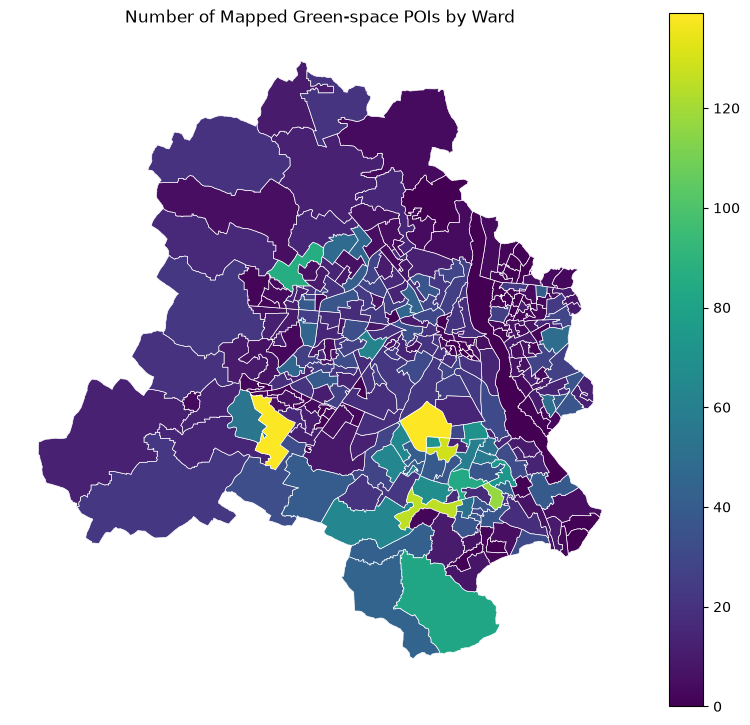

In [18]:
# ============================================================
# MAP 1 — RAW GREEN-SPACE POI COUNT
# ============================================================

fig, ax = plt.subplots(figsize=(10, 9))

green_utm.plot(
    ax=ax,
    column="num_green_pois",
    cmap="viridis",
    legend=True,
    edgecolor="white",
    linewidth=0.5
)

ax.set_title(
    "Number of Mapped Green-space POIs by Ward"
)

ax.set_axis_off()

plt.show()



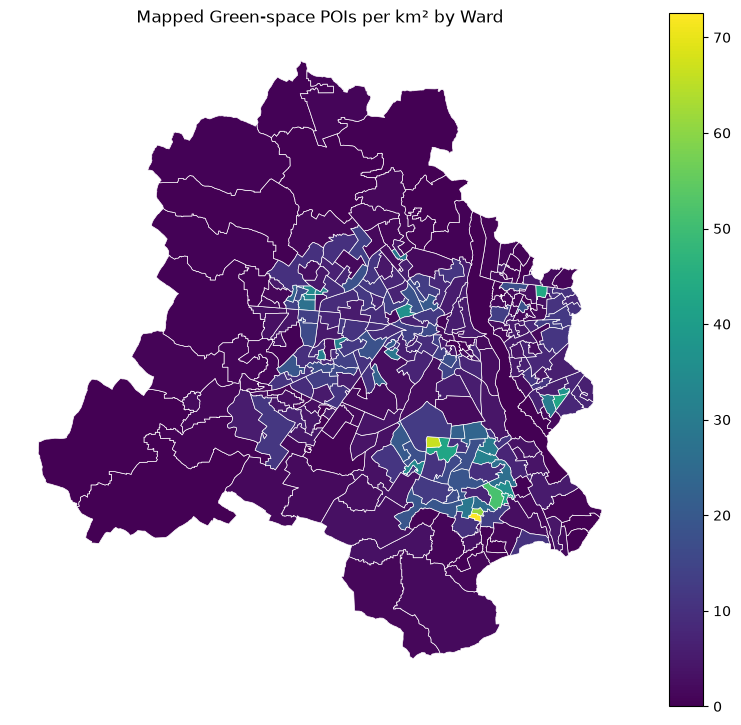

In [19]:
# ============================================================
# MAP 2 — GREEN-SPACE POIs PER KM²
# ============================================================

fig, ax = plt.subplots(figsize=(10, 9))

green_utm.plot(
    ax=ax,
    column="green_poi_density",
    cmap="viridis",
    legend=True,
    edgecolor="white",
    linewidth=0.5
)

ax.set_title(
    "Mapped Green-space POIs per km² by Ward"
)

ax.set_axis_off()

plt.show()




In [20]:

# ============================================================
# OPTIONAL — COMPARE THE TWO MEASURES
# ============================================================

comparison = green_utm[
    [
        "ward_name",
        "num_green_pois",
        "area_km2",
        "green_poi_density"
    ]
].sort_values(
    "green_poi_density",
    ascending=False
)

display(comparison.head(10))

,ward_name,num_green_pois,area_km2,green_poi_density
73,AMBEDKAR NAGAR,36.0,0.496499,72.507686
14,NDMC CHARGE 8,72.0,1.081867,66.551604
74,MADANGIR,30.0,0.493630,60.774276
80,CHITRANJAN PARK,117.0,2.279704,51.322454
38,ASHOK NAGAR,41.0,0.940038,43.615247
13,NDMC CHARGE 7,129.0,3.026380,42.625177
146,DALLOPURA,39.0,0.915244,42.611593
85,GOVIND PURI,22.0,0.523799,42.000858
149,KALYAN PURI,17.0,0.455741,37.301920
157,NIMRI COLONY,46.0,1.262313,36.441048
